# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhammad Anbiya Fatah
- **Email:** ds459b6y1919@student.devacademy.id
- **ID Dicoding:** muhammadanbiya

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

* Pertanyaan 1: Bagaimana tren pertumbuhan total dan rata-rata penyewaan sepeda bulanan (*Month-over-Month*) serta perbandingan rata-rata penyewaan harian berdasarkan musim (`season`) dan kondisi cuaca (`weathersit`) sepanjang periode Januari 2011 hingga Desember 2012, sebagai dasar penentuan jadwal pemeliharaan (*maintenance*) armada dan alokasi kapasitas sepeda musiman?
* Pertanyaan 2: Bagaimana pola rata-rata penyewaan sepeda per jam (`hr`) serta perbandingan rata-rata penyewaan harian antara segmen pengguna *casual* dan *registered* pada hari kerja (*Working Day*) dibandingkan akhir pekan atau hari libur (*Weekend / Holiday*) sepanjang tahun 2011 hingga 2012, sebagai dasar penyusunan jadwal distribusi armada harian dan strategi promosi segmen pengguna?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

## Data Wrangling

### Gathering Data

#### Load Dataset (day.csv dan hour.csv)

In [2]:
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

print("Ukuran day_df :", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)

display(day_df.head())
display(hour_df.head())



Ukuran day_df : (731, 16)
Ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
* Dataset berhasil dimuat dari dua file utama, yaitu `day.csv` (731 baris, 16 kolom) yang merekam agregasi penyewaan harian dan `hour.csv` (17.379 baris, 17 kolom) yang merekam detail penyewaan per jam (`hr`) selama periode 2011–2012.
* Kedua tabel memiliki struktur kolom yang konsisten mencakup variabel waktu, kondisi cuaca, suhu/kelembapan ternormalisasi, serta jumlah pengguna `casual`, `registered`, dan total (`cnt`).

### Assessing Data

#### Identifying Data Quality Problems

In [3]:
print("=== INFO DAY_DF ===")
day_df.info()
print("\nMissing values day_df:\n", day_df.isna().sum())
print("Jumlah duplikasi day_df:", day_df.duplicated().sum())

print("\n=== INFO HOUR_DF ===")
hour_df.info()
print("\nMissing values hour_df:\n", hour_df.isna().sum())
print("Jumlah duplikasi hour_df:", hour_df.duplicated().sum())

display(day_df.describe())
display(hour_df.describe())

invalid_cnt_day = (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum()
invalid_cnt_hour = (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum()
print(f"Inkonsistensi penjumlahan cnt -> day_df: {invalid_cnt_day}, hour_df: {invalid_cnt_hour}")

print("Jumlah baris hum == 0 di day_df  :", (day_df["hum"] == 0).sum())
print("Jumlah baris hum == 0 di hour_df :", (hour_df["hum"] == 0).sum())
print("Jumlah baris atemp == 0 di hour_df:", (hour_df["atemp"] == 0).sum())
print(f"Selisih observasi hour_df vs 731x24: {(len(day_df) * 24) - len(hour_df)} jam")

=== INFO DAY_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing values day_df:
 instant       0
dteday        0
season        0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Inkonsistensi penjumlahan cnt -> day_df: 0, hour_df: 0
Jumlah baris hum == 0 di day_df  : 1
Jumlah baris hum == 0 di hour_df : 22
Jumlah baris atemp == 0 di hour_df: 2
Selisih observasi hour_df vs 731x24: 165 jam


### Steps to Take:
- Mengonversi tipe data kolom `dteday` pada `day_df` dan `hour_df` dari `object` menjadi `datetime64[ns]`.
- Memetakan nilai numerik pada kolom kategorikal (`season`, `yr`, `weekday`, `workingday`, `weathersit`) menjadi label deskriptif agar lebih mudah diinterpretasikan saat proses EDA dan visualisasi.
- Menghapus kolom `instant` yang hanya berfungsi sebagai indeks nomor baris dan tidak relevan untuk analisis bisnis.
- Mempertahankan baris dengan nilai ekstrem `hum = 0.0` dan `atemp = 0.0` serta tidak melakukan imputasi pada 165 jam yang tidak tercatat di `hour_df` agar keutuhan data historis dan deret waktu (*time-series*) tetap terjaga.

### Insight:
- Tidak ditemukan *missing values* maupun data duplikat pada `day_df` maupun `hour_df`, serta seluruh baris memenuhi konsistensi `casual + registered == cnt`.
- Terdapat ketidaksesuaian tipe data pada kolom `dteday` (masih bertipe `object`) serta kolom-kolom kategorikal yang masih direpresentasikan sebagai kode angka (`int64`).
- Pada output `.describe()`, ditemukan nilai minimum `hum = 0.0` pada `day_df` (1 hari pada `2011-03-10` saat cuaca hujan/salju ringan `weathersit = 3`) dan `hour_df` (22 jam pada tanggal yang sama), serta `atemp = 0.0` pada `hour_df` (2 jam pada `2011-01-26`). Nilai ini merupakan anomali pencatatan sensor cuaca/skala normalisasi terendah, namun jumlah penyewaan (`cnt`) tetap valid sehingga baris dipertahankan tanpa penghapusan.
- Jumlah baris `hour_df` sebanyak `17.379` baris memiliki selisih `165` jam dibandingkan `731 × 24 = 17.544` jam pada `day_df` akibat jeda pencatatan operasional sistem historis (seperti cuaca ekstrem Badai Sandy pada akhir Oktober 2012), sehingga tidak diimputasi agar tidak menciptakan data transaksi fiktif.

### Cleaning Data

#### Fixing Data Types and Feature Labels

In [4]:
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
year_map = {0: 2011, 1: 2012}
weather_map = {
    1: "Clear / Partly Cloudy",
    2: "Mist / Cloudy",
    3: "Light Snow / Rain",
    4: "Heavy Rain / Ice"
}
workingday_map = {0: "Weekend / Holiday", 1: "Working Day"}
weekday_map = {
    0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday",
    4: "Thursday", 5: "Friday", 6: "Saturday"
}

def clean_bike_data(df):
    cleaned = df.copy()
    cleaned["dteday"] = pd.to_datetime(cleaned["dteday"])
    cleaned["season_label"] = cleaned["season"].map(season_map)
    cleaned["year"] = cleaned["yr"].map(year_map)
    cleaned["weather_label"] = cleaned["weathersit"].map(weather_map)
    cleaned["day_type"] = cleaned["workingday"].map(workingday_map)
    cleaned["weekday_name"] = cleaned["weekday"].map(weekday_map)
    cleaned.drop(columns=["instant"], inplace=True)
    return cleaned

day_clean = clean_bike_data(day_df)
hour_clean = clean_bike_data(hour_df)

print("Tipe data dteday day_clean :", day_clean["dteday"].dtype)
print("Tipe data dteday hour_clean:", hour_clean["dteday"].dtype)
display(day_clean.head(3))

Tipe data dteday day_clean : datetime64[ns]
Tipe data dteday hour_clean: datetime64[ns]


,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,year,weather_label,day_type,weekday_name
0,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,Spring,2011,Mist / Cloudy,Weekend / Holiday,Saturday
1,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,Spring,2011,Mist / Cloudy,Weekend / Holiday,Sunday
2,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,Spring,2011,Clear / Partly Cloudy,Working Day,Monday


**Insight:**
* Kolom `dteday` pada kedua dataset telah berhasil dikonversi ke format `datetime64[ns]` sehingga siap digunakan untuk analisis deret waktu (*time-series*).
* Penambahan kolom label deskriptif (`season_label`, `year`, `weather_label`, `day_type`, `weekday_name`) membuat hasil agregasi dan grafik langsung terbaca tanpa perlu menerjemahkan kode angka secara manual.

## Exploratory Data Analysis (EDA)

### Explore Penyewaan Sepeda Berdasarkan Waktu, Musim, Cuaca, dan Tipe Pengguna

In [5]:
print("=== TOTAL & PROPORSI PENGGUNA (2011-2012) ===")
total_casual = day_clean["casual"].sum()
total_registered = day_clean["registered"].sum()
total_all = day_clean["cnt"].sum()
print(f"Total Penyewaan : {total_all:,}")
print(f"Casual          : {total_casual:,} ({total_casual/total_all:.2%})")
print(f"Registered      : {total_registered:,} ({total_registered/total_all:.2%})")

print("\n=== PERFORMA TAHUNAN ===")
yearly_summary = day_clean.groupby("year").agg(
    total_rentals=("cnt", "sum"),
    avg_daily_rentals=("cnt", "mean"),
    total_casual=("casual", "sum"),
    total_registered=("registered", "sum")
)
display(yearly_summary)

print("\n=== AGREGASI BERDASARKAN MUSIM ===")
season_summary = day_clean.groupby("season_label").agg(
    total_rentals=("cnt", "sum"),
    avg_daily_rentals=("cnt", "mean"),
    median_rentals=("cnt", "median")
).sort_values(by="total_rentals", ascending=False)
display(season_summary)

print("\n=== AGREGASI BERDASARKAN CUACA ===")
weather_summary = day_clean.groupby("weather_label").agg(
    total_days=("cnt", "count"),
    total_rentals=("cnt", "sum"),
    avg_daily_rentals=("cnt", "mean")
).sort_values(by="avg_daily_rentals", ascending=False)
display(weather_summary)

print("\n=== PERBANDINGAN HARI KERJA VS AKHIR PEKAN/LIBUR ===")
daytype_summary = day_clean.groupby("day_type").agg(
    avg_total=("cnt", "mean"),
    avg_casual=("casual", "mean"),
    avg_registered=("registered", "mean")
)
display(daytype_summary)

print("\n=== AGREGASI BULANAN & PERTUMBUHAN MONTH-OVER-MONTH (MoM) ===")
monthly_eda = day_clean.groupby(["year", "mnth"], as_index=False).agg(
    total_rentals=("cnt", "sum"),
    avg_daily_rentals=("cnt", "mean")
)
monthly_eda["mom_growth_pct"] = (monthly_eda["total_rentals"].pct_change() * 100).round(2)
display(monthly_eda)

=== TOTAL & PROPORSI PENGGUNA (2011-2012) ===
Total Penyewaan : 3,292,679
Casual          : 620,017 (18.83%)
Registered      : 2,672,662 (81.17%)

=== PERFORMA TAHUNAN ===


,total_rentals,avg_daily_rentals,total_casual,total_registered
year,,,,
2011,1243103,3405.761644,247252,995851
2012,2049576,5599.934426,372765,1676811



=== AGREGASI BERDASARKAN MUSIM ===


,total_rentals,avg_daily_rentals,median_rentals
season_label,,,
Fall,1061129,5644.303191,5353.5
Summer,918589,4992.331522,4941.5
Winter,841613,4728.162921,4634.5
Spring,471348,2604.132597,2209.0



=== AGREGASI BERDASARKAN CUACA ===


,total_days,total_rentals,avg_daily_rentals
weather_label,,,
Clear / Partly Cloudy,463,2257952,4876.786177
Mist / Cloudy,247,996858,4035.862348
Light Snow / Rain,21,37869,1803.285714



=== PERBANDINGAN HARI KERJA VS AKHIR PEKAN/LIBUR ===


,avg_total,avg_casual,avg_registered
day_type,,,
Weekend / Holiday,4330.168831,1371.134199,2959.034632
Working Day,4584.820000,606.570000,3978.250000



=== AGREGASI BULANAN & PERTUMBUHAN MONTH-OVER-MONTH (MoM) ===


,year,mnth,total_rentals,avg_daily_rentals,mom_growth_pct
0,2011,1,38189,1231.903226,NaN
1,2011,2,48215,1721.964286,26.25
2,2011,3,64045,2065.967742,32.83
3,2011,4,94870,3162.333333,48.13
4,2011,5,135821,4381.322581,43.17
5,2011,6,143512,4783.733333,5.66
6,2011,7,141341,4559.387097,-1.51
7,2011,8,136691,4409.387097,-3.29
8,2011,9,127418,4247.266667,-6.78
9,2011,10,123511,3984.225806,-3.07


### Insight:
- Total penyewaan sepanjang 2011–2012 mencapai **3.292.679 transaksi**, dengan pengguna `registered` sebesar **81,17%** (2.672.662) dan pengguna `casual` sebesar **18,83%** (620.017). Rata-rata penyewaan harian meningkat sebesar **64,88%** dari tahun 2011 (**3.405,76 penyewaan/hari**, total 1.243.103) ke tahun 2012 (**5.599,93 penyewaan/hari**, total 2.049.576).
- Secara bulanan, penyewaan terendah tercatat pada **Januari 2011** (total **38.189**, rata-rata **1.231,90/hari**) dan memuncak untuk tahun 2011 pada **Juni 2011** (total **143.512**, rata-rata **4.783,73/hari**). Pada tahun 2012, titik terendah tercatat pada **Januari 2012** (total **96.744**, rata-rata **3.120,77/hari**) dan mencapai puncak tertinggi pada **September 2012** (total **218.573**, rata-rata **7.285,77/hari**), dengan lonjakan pertumbuhan *Month-over-Month* (MoM) tertinggi terjadi pada **Februari ke Maret 2012** sebesar **+59,86%** (serta **+48,13%** pada **Maret ke April 2011**).
- Musim **Fall** memiliki rata-rata penyewaan harian tertinggi (**5.644,30 penyewaan/hari**), sedangkan **Spring** memiliki rata-rata terendah (**2.604,13 penyewaan/hari**, atau **53,9%** lebih rendah dari Fall, **47,8%** di bawah Summer, **44,9%** di bawah Winter, dan **42,2%** di bawah rata-rata keseluruhan **4.504,35 penyewaan/hari**).
- Kondisi cuaca **Clear / Partly Cloudy** (463 hari) mencatat rata-rata tertinggi sebesar **4.876,79 penyewaan/hari**, diikuti **Mist / Cloudy** (247 hari) sebesar **4.035,86 penyewaan/hari**, dan **Light Snow / Rain** (21 hari) memiliki rata-rata terendah sebesar **1.803,29 penyewaan/hari**.
- Berdasarkan perbandingan tipe hari, pada **Working Day** rata-rata penyewaan harian didominasi pengguna `registered` sebesar **3.978,25 penyewaan/hari** dibandingkan `casual` sebesar **606,57 penyewaan/hari**. Sebaliknya, pada **Weekend / Holiday**, rata-rata pengguna `casual` meningkat **2,26× lipat** menjadi **1.371,13 penyewaan/hari**, sedangkan `registered` turun menjadi **2.959,03 penyewaan/hari**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren pertumbuhan total dan rata-rata penyewaan sepeda bulanan (*Month-over-Month*) serta perbandingan rata-rata penyewaan harian berdasarkan musim (`season`) dan kondisi cuaca (`weathersit`) sepanjang periode Januari 2011 hingga Desember 2012, sebagai dasar penentuan jadwal pemeliharaan (*maintenance*) armada dan alokasi kapasitas sepeda musiman?

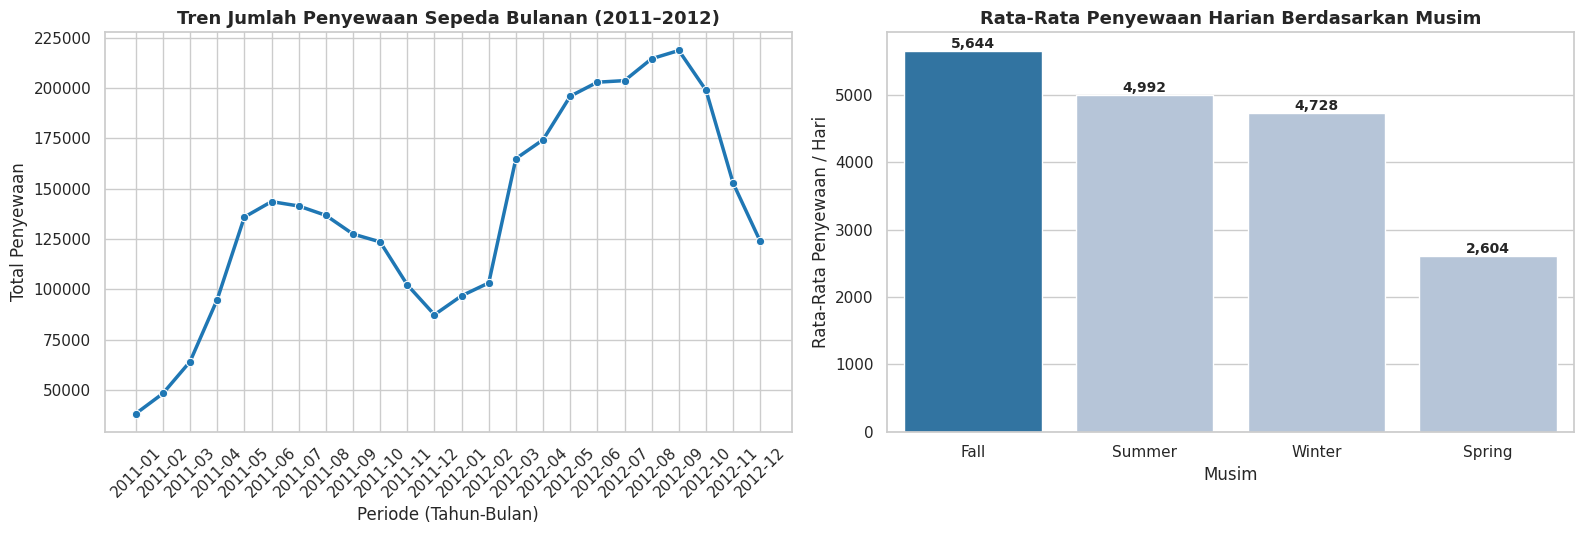

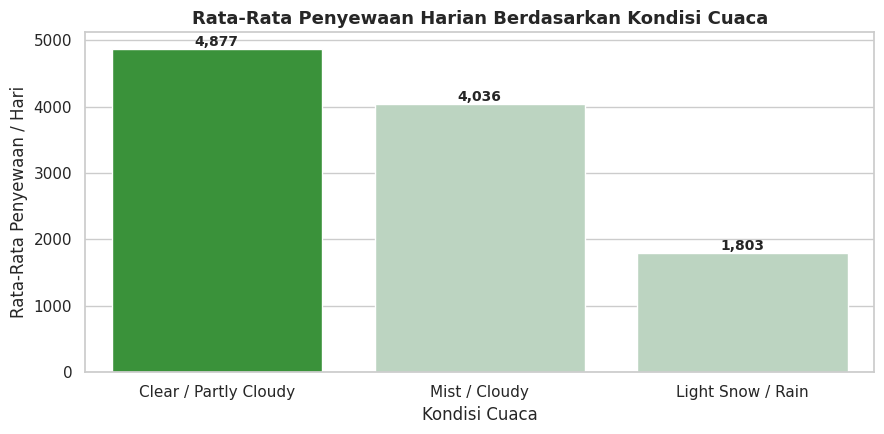

In [6]:
monthly_trend = (
    day_clean.groupby(["year", "mnth"])["cnt"]
    .sum()
    .reset_index()
)
monthly_trend["year_month"] = (
    monthly_trend["year"].astype(str) + "-" + monthly_trend["mnth"].astype(str).str.zfill(2)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Grafik 1: Tren Bulanan 2011-2012
sns.lineplot(
    data=monthly_trend,
    x="year_month",
    y="cnt",
    marker="o",
    linewidth=2.5,
    color="#1f77b4",
    ax=axes[0]
)
axes[0].set_title("Tren Jumlah Penyewaan Sepeda Bulanan (2011–2012)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Periode (Tahun-Bulan)")
axes[0].set_ylabel("Total Penyewaan")
axes[0].tick_params(axis="x", rotation=45)

# Grafik 2: Rata-rata Penyewaan Berdasarkan Musim & Cuaca
season_order = ["Fall", "Summer", "Winter", "Spring"]
season_avg = day_clean.groupby("season_label")["cnt"].mean().reindex(season_order).reset_index()
palette_season = ["#1f77b4" if s == "Fall" else "#b0c4de" for s in season_order]

sns.barplot(
    data=season_avg,
    x="season_label",
    y="cnt",
    hue="season_label",
    palette=palette_season,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Rata-Rata Penyewaan Harian Berdasarkan Musim", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Musim")
axes[1].set_ylabel("Rata-Rata Penyewaan / Hari")

for p in axes[1].patches:
    axes[1].annotate(
        f"{p.get_height():,.0f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom", fontsize=10, fontweight="bold"
    )

plt.tight_layout()
plt.show()

# Grafik Tambahan: Dampak Kondisi Cuaca
weather_order = ["Clear / Partly Cloudy", "Mist / Cloudy", "Light Snow / Rain"]
weather_avg = day_clean.groupby("weather_label")["cnt"].mean().reindex(weather_order).reset_index()
palette_weather = ["#2ca02c" if w == "Clear / Partly Cloudy" else "#b8d8be" for w in weather_order]

plt.figure(figsize=(9, 4.5))
ax_w = sns.barplot(
    data=weather_avg,
    x="weather_label",
    y="cnt",
    hue="weather_label",
    palette=palette_weather,
    legend=False
)
ax_w.set_title("Rata-Rata Penyewaan Harian Berdasarkan Kondisi Cuaca", fontsize=13, fontweight="bold")
ax_w.set_xlabel("Kondisi Cuaca")
ax_w.set_ylabel("Rata-Rata Penyewaan / Hari")

for p in ax_w.patches:
    ax_w.annotate(
        f"{p.get_height():,.0f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom", fontsize=10, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana pola rata-rata penyewaan sepeda per jam (`hr`) serta perbandingan rata-rata penyewaan harian antara segmen pengguna *casual* dan *registered* pada hari kerja (*Working Day*) dibandingkan akhir pekan atau hari libur (*Weekend / Holiday*) sepanjang tahun 2011 hingga 2012, sebagai dasar penyusunan jadwal distribusi armada harian dan strategi promosi segmen pengguna?

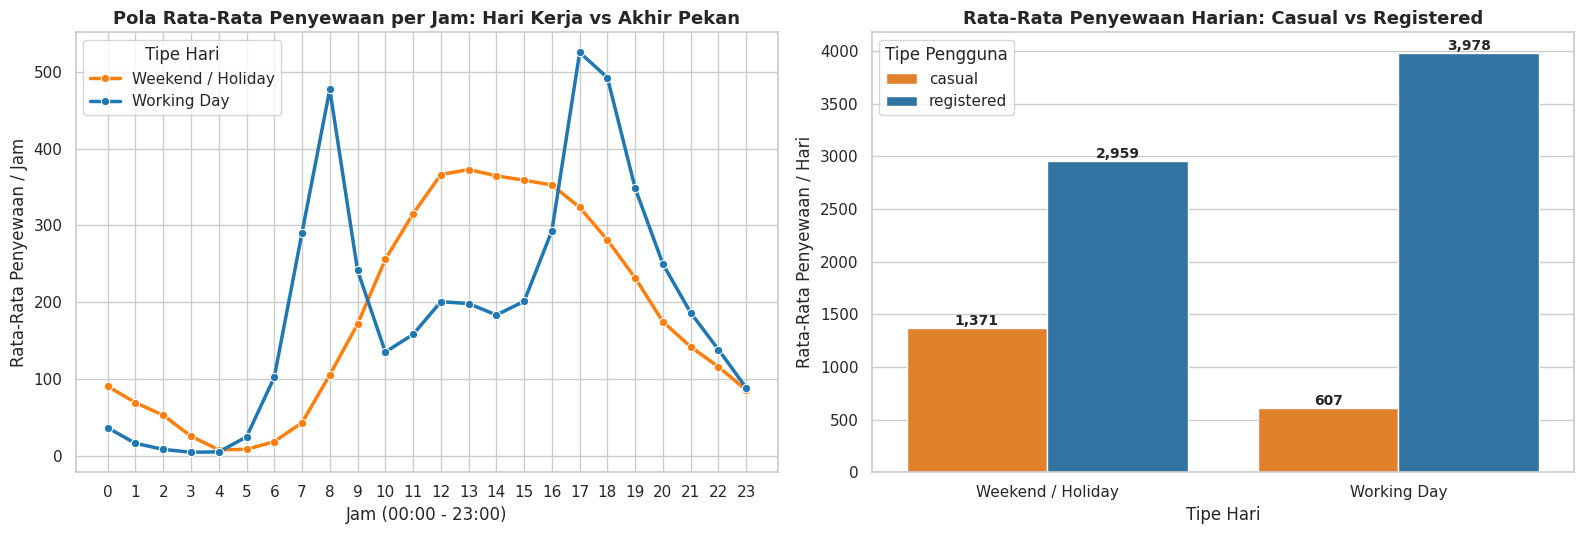

In [7]:
hourly_pattern = (
    hour_clean.groupby(["day_type", "hr"])[["cnt", "casual", "registered"]]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Grafik 1: Pola Penyewaan per Jam (Working Day vs Weekend/Holiday)
sns.lineplot(
    data=hourly_pattern,
    x="hr",
    y="cnt",
    hue="day_type",
    marker="o",
    linewidth=2.5,
    palette={"Working Day": "#1f77b4", "Weekend / Holiday": "#ff7f0e"},
    ax=axes[0]
)
axes[0].set_title("Pola Rata-Rata Penyewaan per Jam: Hari Kerja vs Akhir Pekan", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Jam (00:00 - 23:00)")
axes[0].set_ylabel("Rata-Rata Penyewaan / Jam")
axes[0].set_xticks(range(0, 24))
axes[0].legend(title="Tipe Hari")

# Grafik 2: Perbandingan Komposisi Casual vs Registered
segment_daytype = (
    day_clean.groupby("day_type")[["casual", "registered"]]
    .mean()
    .reset_index()
    .melt(id_vars="day_type", var_name="user_type", value_name="avg_rentals")
)

sns.barplot(
    data=segment_daytype,
    x="day_type",
    y="avg_rentals",
    hue="user_type",
    palette={"casual": "#ff7f0e", "registered": "#1f77b4"},
    ax=axes[1]
)
axes[1].set_title("Rata-Rata Penyewaan Harian: Casual vs Registered", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Tipe Hari")
axes[1].set_ylabel("Rata-Rata Penyewaan / Hari")
axes[1].legend(title="Tipe Pengguna")

for p in axes[1].patches:
    if p.get_height() > 0:
        axes[1].annotate(
            f"{p.get_height():,.0f}",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha="center", va="bottom", fontsize=10, fontweight="bold"
        )

plt.tight_layout()
plt.show()

### Insight:
- **Tren Bulanan, Musim, & Kondisi Cuaca (Pertanyaan 1):** Pada grafik tren bulanan, penyewaan tahun **2011** mulai meningkat sejak **Januari 2011** (38.189) dan mencapai puncaknya pada **Juni 2011** (143.512), lalu menurun bertahap hingga Desember 2011 (dengan nilai September 2011 sebesar 127.418 berada di bawah Mei 2011 sebesar 135.821). Pada tahun **2012**, seluruh bulan mencatat volume lebih tinggi dibandingkan tahun sebelumnya dan mencapai puncak tertinggi pada **September 2012** (218.573). Berdasarkan musim, **Fall** mencatat rata-rata tertinggi (**5.644 penyewaan/hari**) dan **Spring** terendah (**2.604 penyewaan/hari**). Berdasarkan kondisi cuaca, kategori **Clear / Partly Cloudy** (463 hari) memiliki rata-rata tertinggi (**4.877 penyewaan/hari**), sedangkan **Light Snow / Rain** (21 hari) memiliki rata-rata terendah (**1.803 penyewaan/hari**), yang menunjukkan bahwa cuaca buruk jarang terjadi tetapi berkaitan dengan rata-rata penyewaan harian yang jauh lebih rendah.
- **Pola Jam & Tipe Pengguna (Pertanyaan 2):** Pada grafik pola per jam, **Working Day** membentuk distribusi **bimodal (dua puncak tajam)** pada pukul **08:00** dan rentang pukul **17:00–18:00** dengan penurunan pada siang hari. Sebaliknya, pada **Weekend / Holiday**, kurva membentuk pola **unimodal (satu kurva landai)** yang meningkat mulai pagi hari, mencapai puncaknya pada rentang pukul **12:00–16:00**, lalu menurun bertahap hingga malam hari. Pada grafik perbandingan tipe pengguna harian, **Working Day** didominasi oleh pengguna `registered` (**3.978** vs `casual` **607**), sedangkan pada **Weekend / Holiday** rata-rata harian pengguna `casual` meningkat menjadi **1.371 penyewaan/hari** (2,26× lipat dibanding hari kerja) dan `registered` menjadi **2.959 penyewaan/hari**.

## Analisis Lanjutan (Opsional)

,day_type,time_cluster,casual,registered,cnt
0,Weekend / Holiday,Evening Commute (16-19),97.598698,199.741866,297.340564
1,Weekend / Holiday,Midday / Leisure (10-15),120.781385,218.164502,338.945887
2,Weekend / Holiday,Morning Commute (06-09),19.501085,65.498915,85.000000
3,Weekend / Holiday,Night / Off-Peak (20-05),18.109895,59.811296,77.921191
4,Working Day,Evening Commute (16-19),49.182046,365.572718,414.754764
5,Working Day,Midday / Leisure (10-15),40.830707,138.831378,179.662085
6,Working Day,Morning Commute (06-09),15.772681,262.136593,277.909274
7,Working Day,Night / Off-Peak (20-05),10.629078,66.468189,77.097268


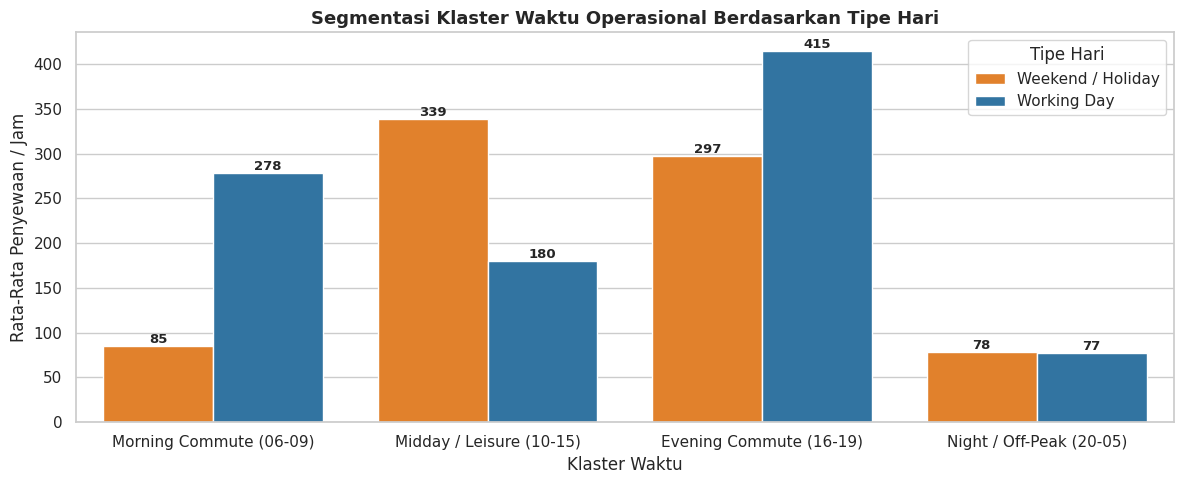

In [8]:
def categorize_time_window(hr):
    if 6 <= hr <= 9:
        return "Morning Commute (06-09)"
    elif 10 <= hr <= 15:
        return "Midday / Leisure (10-15)"
    elif 16 <= hr <= 19:
        return "Evening Commute (16-19)"
    else:
        return "Night / Off-Peak (20-05)"

hour_clean["time_cluster"] = hour_clean["hr"].apply(categorize_time_window)

cluster_summary = (
    hour_clean.groupby(["day_type", "time_cluster"])[["casual", "registered", "cnt"]]
    .mean()
    .reset_index()
)

order_cluster = [
    "Morning Commute (06-09)",
    "Midday / Leisure (10-15)",
    "Evening Commute (16-19)",
    "Night / Off-Peak (20-05)"
]

display(cluster_summary)
plt.figure(figsize=(12, 5))
ax_c = sns.barplot(
    data=cluster_summary,
    x="time_cluster",
    y="cnt",
    hue="day_type",
    order=order_cluster,
    palette={"Working Day": "#1f77b4", "Weekend / Holiday": "#ff7f0e"}
)
ax_c.set_title("Segmentasi Klaster Waktu Operasional Berdasarkan Tipe Hari", fontsize=13, fontweight="bold")
ax_c.set_xlabel("Klaster Waktu")
ax_c.set_ylabel("Rata-Rata Penyewaan / Jam")
ax_c.legend(title="Tipe Hari")

for p in ax_c.patches:
    if p.get_height() > 0:
        ax_c.annotate(
            f"{p.get_height():,.0f}",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha="center", va="bottom", fontsize=9.5, fontweight="bold"
        )

plt.tight_layout()
plt.show()

### Insight:
- Berdasarkan hasil pengelompokan klaster waktu (*time-of-day binning*), pada kategori **Working Day** intensitas penyewaan tertinggi berada pada klaster **Evening Commute (16–19)** dengan rata-rata **415 penyewaan/jam** dan **Morning Commute (06–09)** sebesar **278 penyewaan/jam**, jauh melampaui klaster **Midday / Leisure (10–15)** (**180 penyewaan/jam**) maupun **Night / Off-Peak (20–05)** (**77 penyewaan/jam**).
- Sebaliknya, pada kategori **Weekend / Holiday**, klaster **Midday / Leisure (10–15)** mencatat rata-rata tertinggi sebesar **339 penyewaan/jam**. Namun, permintaan tidak berpindah sepenuhnya ke siang hari karena klaster **Evening Commute (16–19)** pada akhir pekan/hari libur tetap mencatat rata-rata tinggi sebesar **297 penyewaan/jam** (sekitar **87,6%** dari rata-rata klaster Midday / Leisure), sehingga operasional armada tetap perlu dijaga tinggi dari siang hingga sore hari.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata penyewaan sepeda harian meningkat sebesar **64,88%** dari **3.405,76 penyewaan/hari** (total 1.243.103) pada tahun 2011 menjadi **5.599,93 penyewaan/hari** (total 2.049.576) pada tahun 2012. Secara bulanan, penyewaan terendah terjadi pada **Januari 2011** (total **38.189**, rata-rata **1.231,90/hari**) dan memuncak pada **Juni 2011** (total **143.512**, rata-rata **4.783,73/hari**) untuk tahun 2011, sedangkan pada tahun 2012 terendah pada **Januari 2012** (total **96.744**, rata-rata **3.120,77/hari**) dan memuncak pada **September 2012** (total **218.573**, rata-rata **7.285,77/hari**), dengan lonjakan pertumbuhan *Month-over-Month* tertinggi pada **Februari ke Maret 2012** (**+59,86%**). Berdasarkan musim, **Fall** memiliki rata-rata penyewaan harian tertinggi (**5.644,30 penyewaan/hari**) dan **Spring** memiliki rata-rata terendah (**2.604,13 penyewaan/hari**). Berdasarkan cuaca, kategori **Clear / Partly Cloudy** memiliki rata-rata tertinggi (**4.876,79 penyewaan/hari**), sedangkan **Light Snow / Rain** memiliki rata-rata terendah (**1.803,29 penyewaan/hari**).
- **Conclusion pertanyaan 2:** Pola penyewaan per jam pada **Working Day** membentuk dua puncak tajam pada pukul **08:00** dan **17:00–18:00** (klaster **Evening Commute (16–19)** rata-rata **415 penyewaan/jam** dan **Morning Commute (06–09)** rata-rata **278 penyewaan/jam**), sedangkan pada **Weekend / Holiday** membentuk kurva landai dengan puncak pada pukul **12:00–16:00** (klaster **Midday / Leisure (10–15)** rata-rata **339 penyewaan/jam**, diikuti **Evening Commute (16–19)** sebesar **297 penyewaan/jam**). Dari sisi segmen pengguna, rata-rata penyewaan harian pada **Working Day** didominasi pengguna `registered` (**3.978,25** vs `casual` **606,57**), sedangkan pada **Weekend / Holiday** rata-rata harian pengguna `casual` meningkat **2,26× lipat** menjadi **1.371,13 penyewaan/hari** dan `registered` menjadi **2.959,03 penyewaan/hari**.

**Rekomendasi Action Item:**
- **Penjadwalan Pemeliharaan Armada pada Musim Spring:** Jadwalkan pemeliharaan besar (*overhaul*), inspeksi menyeluruh, dan peremajaan unit sepeda pada musim **Spring** saat rata-rata penyewaan harian berada di level terendah (**2.604,13 penyewaan/hari**, atau lebih rendah **53,9%** dibandingkan musim puncak **Fall** sebesar **5.644,30 penyewaan/hari** dan **42,2%** di bawah rata-rata keseluruhan **4.504,35 penyewaan/hari**), sehingga seluruh armada siap beroperasi penuh menghadapi lonjakan permintaan pada periode **Juni–September**.
- **Optimalisasi Distribusi Armada Harian Berdasarkan Klaster Waktu dan Tipe Hari:**
  - Pada **Working Day**, prioritaskan kesiapan armada dan penyeimbangan stok (*rebalancing*) menjelang jam sibuk pagi (**06:00–09:59**, rata-rata **278 penyewaan/jam**) dan sore (**16:00–19:59**, rata-rata **415 penyewaan/jam**) guna mengakomodasi tingginya permintaan harian pengguna `registered` (**3.978,25 penyewaan/hari**).
  - Pada **Weekend / Holiday**, pertahankan ketersediaan kapasitas armada secara merata dari siang hingga sore hari (**10:00–19:59**)—yang mencakup klaster **Midday / Leisure** (**339 penyewaan/jam**) dan **Evening Commute** (**297 penyewaan/jam**)—serta luncurkan kampanye promosi tarif harian atau paket khusus akhir pekan/hari libur untuk menarik lonjakan segmen pengguna `casual` (**1.371,13 penyewaan/hari**).